# A/B-тест email-рассылки интернет-магазина (Hillstrom)

Данные: [MineThatData E-Mail Analytics Challenge](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html), Kevin Hillstrom, 2008. 64 000 клиентов, которые покупали в магазине за последние 12 месяцев, случайно разделены на три группы:

- **Mens E-Mail** — письмо с мужскими товарами;
- **Womens E-Mail** — письмо с женскими товарами;
- **No E-Mail** — контроль, письмо не отправлялось.

Поведение отслеживалось 2 недели после рассылки: `visit` — зашел на сайт, `conversion` — купил, `spend` — сумма покупок в долларах.

Признаки до рассылки: `recency` — месяцев с последней покупки, `history` — сумма покупок за год, `mens` / `womens` — покупал мужские / женские товары, `newbie` — новый клиент за последние 12 месяцев, `zip_code` — тип района, `channel` — канал прошлых покупок.

**Гипотезы.** H0: рассылка не меняет метрику по сравнению с контролем; H1: меняет. Отдельно сравниваем мужское письмо с женским.
**Метрики.** Основная — выручка на клиента (`spend`), дополнительные — доля заходов на сайт и конверсия в покупку.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e7eb", "axes.axisbelow": True})
COLORS = {"control": "#9aa5b1", "mens": "#2a6fbb", "womens": "#d9822b"}
LABELS = {"control": "Без письма", "mens": "Мужское письмо", "womens": "Женское письмо"}

df = pd.read_csv("в")
df["group"] = df.segment.map({"No E-Mail": "control", "Mens E-Mail": "mens", "Womens E-Mail": "womens"})
df.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,group
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0,womens
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0,control
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0,womens
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0,mens
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0,womens


In [4]:
df.isna().sum().sum(), df.shape

(np.int64(0), (64000, 13))

## Корректность эксперимента

**SRM (sample ratio mismatch).** Если группы задумывались равными, их размеры должны отличаться только случайно. Проверяем критерием хи-квадрат.

In [5]:
sizes = df.group.value_counts()
srm = stats.chisquare(sizes.values)
pd.Series({**sizes.to_dict(), "chi2": round(srm.statistic, 3), "p-value": round(srm.pvalue, 3)})

womens     21387.000
mens       21307.000
control    21306.000
chi2           0.203
p-value        0.904
dtype: float64

**Баланс признаков.** Признаки измерены до рассылки, поэтому при корректной рандомизации они не должны различаться между группами. Смотрим стандартизованную разность средних (SMD, хороший баланс — |SMD| < 0,1) и p-value: Краскел-Уоллис для чисел, хи-квадрат для категорий.

In [6]:
def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

rows = []
for col in ["recency", "history", "mens", "womens", "newbie"]:
    ctrl = df[df.group == "control"][col]
    rows.append({"признак": col,
                 "control": round(ctrl.mean(), 3),
                 "mens": round(df[df.group == "mens"][col].mean(), 3),
                 "womens": round(df[df.group == "womens"][col].mean(), 3),
                 "SMD mens": round(smd(df[df.group == "mens"][col], ctrl), 3),
                 "SMD womens": round(smd(df[df.group == "womens"][col], ctrl), 3),
                 "p-value": round(stats.kruskal(*[g[col] for _, g in df.groupby("group")]).pvalue, 3)})
for col in ["zip_code", "channel", "history_segment"]:
    rows.append({"признак": col, "p-value": round(stats.chi2_contingency(pd.crosstab(df[col], df.group)).pvalue, 3)})
pd.DataFrame(rows).set_index("признак")

,control,mens,womens,SMD mens,SMD womens,p-value
признак,,,,,,
recency,5.750,5.774,5.768,0.007,0.005,0.794
history,240.883,242.836,242.537,0.008,0.007,0.667
mens,0.553,0.551,0.549,-0.005,-0.009,0.672
womens,0.548,0.551,0.550,0.008,0.005,0.729
newbie,0.502,0.502,0.503,-0.001,0.003,0.934
zip_code,NaN,NaN,NaN,NaN,NaN,0.579
channel,NaN,NaN,NaN,NaN,NaN,0.458
history_segment,NaN,NaN,NaN,NaN,NaN,0.358


Размеры групп и все признаки сбалансированы: SRM p = 0,90, все |SMD| < 0,01, все p-value > 0,3. Различия в метриках можно приписывать рассылке.

## Метрики по группам

In [7]:
metrics = df.groupby("group").agg(n=("visit", "size"), visit_rate=("visit", "mean"),
                                  conversion_rate=("conversion", "mean"), spend_per_client=("spend", "mean"),
                                  buyers=("conversion", "sum"))
metrics[["visit_rate", "conversion_rate"]] *= 100
metrics.round(3)

,n,visit_rate,conversion_rate,spend_per_client,buyers
group,,,,,
control,21306,10.617,0.573,0.653,122
mens,21307,18.276,1.253,1.423,267
womens,21387,15.140,0.884,1.077,189


## Статистические тесты

- Доли (заходы, конверсия) — z-тест для двух долей, доверительный интервал для разности.
- Выручка на клиента — 99% клиентов ничего не купили, распределение с длинным хвостом. Основной тест — t-тест Уэлча (по ЦПТ при 21 тыс. наблюдений в группе среднее распределено нормально), интервал — бутстрэп. Манн-Уитни приводим для сравнения: он проверяет сдвиг распределений, а не разницу средних.
- Три сравнения на метрику (мужское и женское против контроля, мужское против женского) — поправка Холма на множественные сравнения.

In [8]:
PAIRS = [("mens", "control"), ("womens", "control"), ("mens", "womens")]
rng = np.random.default_rng(0)

def holm(p):
    p = np.asarray(p)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0
    for rank, i in enumerate(order):
        running = max(running, min(1, (len(p) - rank) * p[i]))
        adj[i] = running
    return adj

def prop_test(a, b):
    x1, n1, x0, n0 = a.sum(), len(a), b.sum(), len(b)
    p1, p0, p = x1 / n1, x0 / n0, (x1 + x0) / (n1 + n0)
    z = (p1 - p0) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n0))
    se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    return p1 - p0, p1 - p0 - 1.96 * se, p1 - p0 + 1.96 * se, p1 / p0 - 1, 2 * stats.norm.sf(abs(z))

rows = []
for metric in ["visit", "conversion"]:
    res = [prop_test(df[df.group == a][metric], df[df.group == b][metric]) for a, b in PAIRS]
    for (a, b), r, p_adj in zip(PAIRS, res, holm([r[4] for r in res])):
        rows.append({"метрика": metric, "сравнение": f"{a} vs {b}", "разница, п.п.": r[0] * 100,
                     "ci_low": r[1] * 100, "ci_high": r[2] * 100, "относительно, %": r[3] * 100,
                     "p-value": r[4], "p-value (Холм)": p_adj})
props = pd.DataFrame(rows)
props.round({"разница, п.п.": 2, "ci_low": 2, "ci_high": 2, "относительно, %": 1})

,метрика,сравнение,"разница, п.п.",ci_low,ci_high,"относительно, %",p-value,p-value (Холм)
0,visit,mens vs control,7.66,7.00,8.32,72.1,5.685165e-112,1.705550e-111
1,visit,womens vs control,4.52,3.89,5.16,42.6,3.182403e-44,6.364806e-44
2,visit,mens vs womens,3.14,2.43,3.84,20.7,3.802165e-18,3.802165e-18
3,conversion,mens vs control,0.68,0.50,0.86,118.8,1.523224e-13,4.569671e-13
4,conversion,womens vs control,0.31,0.15,0.47,54.3,1.571051e-04,3.142103e-04
5,conversion,mens vs womens,0.37,0.17,0.56,41.8,2.051538e-04,3.142103e-04


In [9]:
def boot_diff(a, b, n=5000):
    return np.percentile([rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(n)], [2.5, 97.5])

rows = []
for a, b in PAIRS:
    x, y = df[df.group == a].spend.values, df[df.group == b].spend.values
    lo, hi = boot_diff(x, y)
    rows.append({"сравнение": f"{a} vs {b}", "разница, $": x.mean() - y.mean(), "ci_low": lo, "ci_high": hi,
                 "относительно, %": (x.mean() / y.mean() - 1) * 100,
                 "p-value (Уэлч)": stats.ttest_ind(x, y, equal_var=False).pvalue,
                 "p-value (Манн-Уитни)": stats.mannwhitneyu(x, y).pvalue})
spend = pd.DataFrame(rows)
spend["p-value (Уэлч, Холм)"] = holm(spend["p-value (Уэлч)"])
spend.round({"разница, $": 3, "ci_low": 3, "ci_high": 3, "относительно, %": 1})

,сравнение,"разница, $",ci_low,ci_high,"относительно, %",p-value (Уэлч),p-value (Манн-Уитни),"p-value (Уэлч, Холм)"
0,mens vs control,0.770,0.492,1.052,117.9,1.163815e-07,1.581999e-13,3.491445e-07
1,womens vs control,0.424,0.167,0.673,65.0,1.129397e-03,1.554517e-04,2.258794e-03
2,mens vs womens,0.345,0.032,0.660,32.1,3.046865e-02,2.135675e-04,3.046865e-02


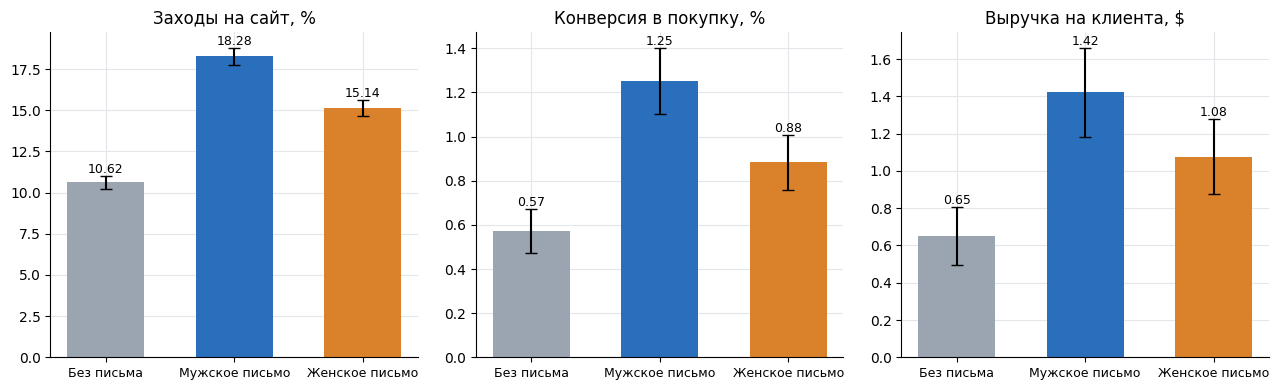

In [10]:
def mean_ci(x):
    se = x.std() / np.sqrt(len(x))
    return x.mean(), 1.96 * se

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (metric, title, k) in zip(axes, [("visit", "Заходы на сайт, %", 100), ("conversion", "Конверсия в покупку, %", 100),
                                          ("spend", "Выручка на клиента, $", 1)]):
    for i, g in enumerate(["control", "mens", "womens"]):
        m, e = mean_ci(df[df.group == g][metric])
        ax.bar(i, m * k, yerr=e * k, color=COLORS[g], capsize=4, width=0.6)
        ax.text(i, m * k + e * k, f"{m * k:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(3))
    ax.set_xticklabels([LABELS[g] for g in ["control", "mens", "womens"]], fontsize=9)
    ax.set_title(title)
plt.tight_layout()
plt.show()

Все три метрики значимо выросли для обоих писем, в том числе после поправки Холма. Мужское письмо лучше женского по заходам и конверсии; по выручке разница $0,35 значима на грани (p = 0,03 после поправки), и она меньше MDE — к этому сравнению стоит относиться осторожно.

## MDE: какой эффект тест мог заметить

При α = 0,05, мощности 80% и ~21,3 тыс. клиентов в группе.

In [11]:
z = stats.norm.ppf(0.975) + stats.norm.ppf(0.8)
n = len(df) / 3
ctrl = df[df.group == "control"]
mde = pd.DataFrame({
    "базовый уровень": [ctrl.visit.mean() * 100, ctrl.conversion.mean() * 100, ctrl.spend.mean()],
    "MDE (абсолютный)": [z * np.sqrt(2 * p * (1 - p) / n) * 100 for p in (ctrl.visit.mean(), ctrl.conversion.mean())]
                        + [z * df.spend.std() * np.sqrt(2 / n)],
}, index=["заходы, %", "конверсия, %", "выручка на клиента, $"])
mde["MDE (относительный), %"] = mde["MDE (абсолютный)"] / mde["базовый уровень"] * 100
mde.round(3)

,базовый уровень,MDE (абсолютный),"MDE (относительный), %"
"заходы, %",10.617,0.836,7.871
"конверсия, %",0.573,0.205,35.745
"выручка на клиента, $",0.653,0.408,62.483


Наблюдаемые эффекты писем против контроля (+7,7 и +4,5 п.п. заходов, +$0,77 и +$0,42 выручки) больше MDE, то есть тест был достаточно мощным. Разница мужского и женского письма по выручке ($0,35) меньше MDE ($0,41).

## Средний чек покупателей

Средний чек считается только по купившим, а кто купит — зависит от письма. Поэтому это описательная метрика, а не причинный эффект.

In [12]:
buyers = df[df.conversion == 1]
aov = buyers.groupby("group").spend.agg(["count", "mean", "median"]).round(2)
aov["ci_low"], aov["ci_high"] = zip(*[np.percentile([rng.choice(buyers[buyers.group == g].spend.values, n_g).mean()
                                                      for _ in range(3000)], [2.5, 97.5]).round(1)
                                      for g, n_g in aov["count"].items()])
aov

,count,mean,median,ci_low,ci_high
group,,,,,
control,122,114.00,88.36,97.2,133.0
mens,267,113.53,66.98,99.8,127.3
womens,189,121.89,94.71,107.4,137.3


Средний чек у всех групп около $114–122 с широкими интервалами, различий нет. Рост выручки обеспечен тем, что покупателей стало больше, а не тем, что они тратят больше.

## Сегменты: кому какое письмо помогает

Разведочный анализ: эффект (разница с контролем) внутри сегментов. Сегментов много, поэтому отдельные значимые результаты могут быть случайными — опираемся на крупные и устойчивые различия.

In [13]:
df["buy_history"] = np.select([(df.mens == 1) & (df.womens == 0), (df.mens == 0) & (df.womens == 1)],
                              ["только мужское", "только женское"], "мужское и женское")
df["recency_group"] = pd.cut(df.recency, [0, 3, 6, 9, 12], labels=["1-3 мес", "4-6 мес", "7-9 мес", "10-12 мес"])
df["history_group"] = pd.cut(df.history, [0, 100, 350, 4000], labels=["< $100", "$100-350", "> $350"])

def uplift(sub, metric, g):
    a, b = sub[sub.group == g][metric], sub[sub.group == "control"][metric]
    return a.mean() - b.mean(), np.sqrt(a.var() / len(a) + b.var() / len(b))

rows = []
for seg in ["buy_history", "newbie", "channel", "zip_code", "recency_group", "history_group"]:
    for level, sub in df.groupby(seg, observed=True):
        r = {"сегмент": seg, "значение": level, "клиентов": len(sub)}
        for g in ["mens", "womens"]:
            v, v_se = uplift(sub, "visit", g)
            s, s_se = uplift(sub, "spend", g)
            r[f"{g}: заходы, п.п."] = f"{v * 100:+.1f} ± {1.96 * v_se * 100:.1f}"
            r[f"{g}: выручка, $"] = f"{s:+.2f} ± {1.96 * s_se:.2f}"
        rows.append(r)
pd.DataFrame(rows).set_index(["сегмент", "значение"])

клиентов mens: заходы, п.п. mens: выручка, $ womens: заходы, п.п. womens: выручка, $
сегмент       значение                                                                                               
buy_history   мужское и женское      6448        +13.4 ± 2.5     +1.82 ± 1.33           +7.1 ± 2.5       +0.16 ± 0.98
              только женское        28734         +7.1 ± 1.0     +0.62 ± 0.35           +7.4 ± 1.0       +0.63 ± 0.34
              только мужское        28818         +6.9 ± 1.0     +0.68 ± 0.44           +1.1 ± 0.9       +0.28 ± 0.40
newbie        0                     31856         +7.8 ± 1.0     +0.58 ± 0.44           +4.0 ± 1.0       +0.11 ± 0.39
              1                     32144         +7.5 ± 0.9     +0.96 ± 0.37           +5.0 ± 0.8       +0.73 ± 0.33
channel       Multichannel           7762         +8.3 ± 2.0     +1.21 ± 0.82           +4.7 ± 2.0       +1.16 ± 0.90
              Phone                 28021         +7.6 ± 0.9     +0.56 ± 0.40           +4.5 ± 0.9       +0.23 ± 0.35
              Web                   28217         +7.6 ± 1.0     +0.85 ± 0.45           +4.6 ± 1.0       +0.42 ± 0.39
zip_code      Rural                  9563         +7.3 ± 1.9     +0.76 ± 0.70           +2.9 ± 1.8       +0.51 ± 0.63
              Surburban             28776         +7.4 ± 1.0     +0.80 ± 0.45           +4.9 ± 0.9       +0.18 ± 0.37
              Urban                 25661         +8.0 ± 1.0     +0.74 ± 0.43           +4.7 ± 1.0       +0.67 ± 0.42
recency_group 1-3 мес               22393         +8.5 ± 1.2     +1.05 ± 0.58           +4.4 ± 1.2       +0.36 ± 0.47
              4-6 мес               14192         +7.6 ± 1.4     +0.49 ± 0.48           +4.0 ± 1.3       +0.67 ± 0.56
              7-9 мес               14014         +7.0 ± 1.3     +0.61 ± 0.54           +5.4 ± 1.3       +0.30 ± 0.55
              10-12 мес             13401         +7.0 ± 1.3     +0.77 ± 0.56           +4.4 ± 1.2       +0.41 ± 0.43
history_group < $100                22972         +6.9 ± 1.0     +0.54 ± 0.43           +4.7 ± 1.0       +0.63 ± 0.44
              $100-350              26541         +7.7 ± 1.0     +0.63 ± 0.42           +4.0 ± 1.0       +0.10 ± 0.34
              > $350                14487         +9.0 ± 1.5     +1.40 ± 0.72           +5.2 ± 1.5       +0.70 ± 0.63

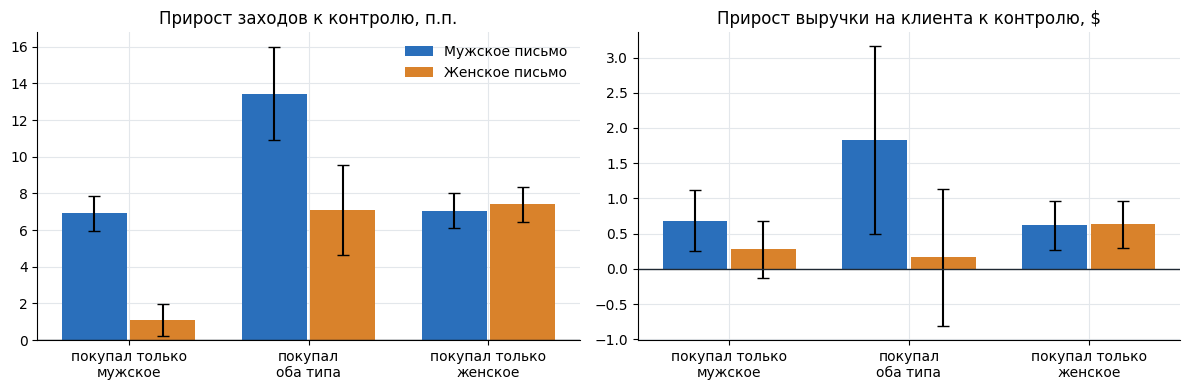

In [14]:
order = ["только мужское", "мужское и женское", "только женское"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (metric, title, k) in zip(axes, [("visit", "Прирост заходов к контролю, п.п.", 100),
                                          ("spend", "Прирост выручки на клиента к контролю, $", 1)]):
    for j, g in enumerate(["mens", "womens"]):
        vals = [uplift(df[df.buy_history == h], metric, g) for h in order]
        x = np.arange(3) + (j - 0.5) * 0.38
        ax.bar(x, [v[0] * k for v in vals], 0.36, yerr=[1.96 * v[1] * k for v in vals], capsize=4,
               color=COLORS[g], label=LABELS[g])
    ax.axhline(0, color="#1f2933", lw=1)
    ax.set_xticks(range(3))
    ax.set_xticklabels(["покупал только\nмужское", "покупал\nоба типа", "покупал только\nженское"])
    ax.set_title(title)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

In [15]:
def interaction(metric, g, seg_a, seg_b):
    (ea, sa), (eb, sb) = uplift(df[df.buy_history == seg_a], metric, g), uplift(df[df.buy_history == seg_b], metric, g)
    zval = (ea - eb) / np.sqrt(sa ** 2 + sb ** 2)
    return round((ea - eb) * 100, 2), 2 * stats.norm.sf(abs(zval))

pd.DataFrame({g: interaction("visit", g, "только женское", "только мужское") for g in ["mens", "womens"]},
             index=["разница эффектов (женское - мужское), п.п.", "p-value"]).T

,"разница эффектов (женское - мужское), п.п.",p-value
mens,0.14,8.364598e-01
womens,6.29,1.161888e-21


Главная неоднородность — история покупок:

- **женское письмо** почти не действует на тех, кто покупал только мужское (+1,1 п.п. заходов), а на покупательниц женского действует так же, как мужское письмо (+7,4 п.п.); разница эффектов значима (p < 0,001);
- **мужское письмо** работает одинаково на «мужских» и «женских» покупателей (+6,9 и +7,1 п.п.) и сильнее всего — на тех, кто покупал оба типа (+13,4 п.п., +$1,82 выручки);
- по остальным признакам (новизна клиента, канал, район, давность покупки) эффект мужского письма стабилен, явной неоднородности нет.

## Какую рассылку выбрать

Сравниваем стратегии по выручке на клиента. Благодаря рандомизации ценность стратегии оценивается по клиентам, которые случайно получили то, что стратегия рекомендует для их сегмента. Интервалы — бутстрэп.

In [16]:
POLICIES = {
    "Без писем": lambda x: pd.Series("control", index=x.index),
    "Женское всем": lambda x: pd.Series("womens", index=x.index),
    "Мужское всем": lambda x: pd.Series("mens", index=x.index),
    "Женское покупательницам женского, остальным мужское":
        lambda x: pd.Series(np.where(x.buy_history == "только женское", "womens", "mens"), index=x.index),
}

def policy_value(data, policy):
    chosen = data[data.group == policy(data)]
    return chosen.spend.mean(), chosen.visit.mean() * 100

boot = []
for seed in range(300):
    sample = df.sample(frac=1, replace=True, random_state=seed)
    boot.append({name: policy_value(sample, policy)[0] for name, policy in POLICIES.items()})
boot = pd.DataFrame(boot)

rows = []
for name, policy in POLICIES.items():
    spend_v, visit_v = policy_value(df, policy)
    rows.append({"стратегия": name, "выручка на клиента, $": spend_v,
                 "ci_low": boot[name].quantile(0.025), "ci_high": boot[name].quantile(0.975), "заходы, %": visit_v})
pd.DataFrame(rows).set_index("стратегия").round(3)

,"выручка на клиента, $",ci_low,ci_high,"заходы, %"
стратегия,,,,
Без писем,0.653,0.496,0.809,10.617
Женское всем,1.077,0.873,1.294,15.140
Мужское всем,1.423,1.192,1.669,18.276
"Женское покупательницам женского, остальным мужское",1.429,1.218,1.699,18.423


In [17]:
diff = boot["Женское покупательницам женского, остальным мужское"] - boot["Мужское всем"]
pd.Series({"разница таргетинга с «мужское всем», $": diff.mean(),
           "ci_low": diff.quantile(0.025), "ci_high": diff.quantile(0.975)}).round(3)

разница таргетинга с «мужское всем», $    0.014
ci_low                                   -0.163
ci_high                                   0.184
dtype: float64

In [18]:
uplift_per_client = df[df.group == "mens"].spend.mean() - df[df.group == "control"].spend.mean()
lo, hi = spend.loc[0, ["ci_low", "ci_high"]]
pd.Series({"прирост выручки на клиента, $": round(uplift_per_client, 2),
           "на всю базу 64 000 клиентов за 2 недели, $": round(uplift_per_client * len(df)),
           "нижняя граница, $": round(lo * len(df)), "верхняя граница, $": round(hi * len(df))})

прирост выручки на клиента, $                     0.77
на всю базу 64 000 клиентов за 2 недели, $    49269.00
нижняя граница, $                             31505.00
верхняя граница, $                            67328.00
dtype: float64

## Выводы

1. Эксперимент корректный: группы равны по размеру и сбалансированы по всем признакам.
2. Обе рассылки значимо увеличивают заходы, конверсию и выручку. Мужское письмо: +7,7 п.п. заходов (+72%), конверсия 0,57% → 1,25%, выручка на клиента $0,65 → $1,42. Женское: +4,5 п.п., 0,88%, $1,08.
3. Рост выручки обеспечен числом покупателей, средний чек не меняется.
4. Женское письмо не работает на клиентов, покупавших только мужские товары; мужское работает на всех.
5. Таргетинг по истории покупок не дает выигрыша по сравнению с мужским письмом всей базе.

**Рекомендация:** отправлять мужское письмо всей базе — около +$49 тыс. выручки за 2 недели (95% ДИ $31–67 тыс.) на 64 тыс. клиентов. Решение стоит подтвердить с учетом маржи и стоимости рассылки — в данных есть только выручка.

**Гипотезы для следующих тестов:**

- почему мужское письмо работает и на покупательниц женского: проверить письмо с товарами обоих типов против мужского;
- для клиентов, покупавших оба типа товаров, эффект почти вдвое выше — проверить для них более частые рассылки;
- добавить защитные метрики (отписки, жалобы на спам) и измерить долгосрочный эффект на отложенной контрольной группе: две недели не показывают, не забирает ли рассылка будущие покупки.